<a href="https://colab.research.google.com/github/amavi-e/A-TinyML-Powered-Wearable-Navigation-Aid-for-the-Visually-Impaired/blob/model-training/irp_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FYP model training v3 - class + distance model, int8 quantization, alert priorities and speech clips
TinyML wearable navigation aid. This is the **training notebook** (the dataset is built in the separate preprocessing notebook).

**Use a GPU runtime:** Runtime > Change runtime type > **T4 GPU**. Training needs it (CPU would take days). Conversion, evaluation and speech generation run on the CPU part of the same machine. Run the cells top to bottom; cell 0 refuses to continue without a GPU.

**Needs:** `FYP/final_dataset.tar` on Drive (27 classes x 1000 images, split 800/100/100).

**What the model does:** for every camera frame it outputs (1) the class of the main object and (2) its *apparent size* (square root of the box area). The size is turned into an approximate distance in metres, then into a distance band and a priority; each (class, band) pair has a pre-recorded speech clip.

**Compression order (as agreed with the supervisor):** int8 post-training quantization is the main step. Pruning runs only if the int8 file is still bigger than `TARGET_MB`. A candidate is accepted only if class accuracy, size accuracy and the 'fully integer' check all stay within the limits in cell 0.

**Things you will want to edit:** `CLASS_INFO` in cell 1 (typical object sizes and hazard levels), `HFOV_DEG` and `BAND_LIMITS_M` in cell 0, `CONF_MIN`, `TARGET_MB`. The metre values are estimates from apparent size, so check them with a few photos of objects at known distances taken with the real camera.

**Estimated time on a T4:** roughly 1.5-2 hours in the worst case (both training phases use early stopping, so often less). This is an estimate, not a measurement.

**Files written** (local `/content/model_out`, copied to `FYP/fyp-model-v3` on Drive at the end): the final `.tflite`, the other candidates, float model and weights, training curves, `alert_config.json` and the `audio/` folder with 81 WAV clips.

## Part A - Setup, class table and rules

In [ ]:
# CELL 0 - SETUP: Keras switch, installs, GPU check, Drive, paths and every setting you may want to change. Run this first in every session.
import os, sys, subprocess   # operating-system, interpreter and process tools
LOADED_EARLY = 'tensorflow' in sys.modules and os.environ.get('TF_USE_LEGACY_KERAS') != '1'   # True if TensorFlow was imported before the switch below could be set
os.environ['TF_USE_LEGACY_KERAS'] = '1'   # make tf.keras the classic Keras 2 (tf_keras): the pruning toolkit only works with it
if LOADED_EARLY:   # the switch came too late
    raise RuntimeError('TensorFlow was already imported. Use Runtime > Restart session, then run this cell first.')   # tell the user what to do
import importlib.metadata as md   # reads installed package versions without importing them
for pkg in ('tensorflow', 'tensorflow-cpu'):   # the TensorFlow package may be listed under either name
    try:   # ask for its version
        TF_VERSION = md.version(pkg); break   # found it
    except md.PackageNotFoundError:   # not installed under this name
        continue   # try the next name
TF_MM = '.'.join(TF_VERSION.split('.')[:2])   # major.minor, for example 2.20
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', f'tf_keras~={TF_MM}.0', 'tensorflow-model-optimization', 'gTTS'], check=True)   # install a tf_keras that matches TensorFlow (a mismatch would upgrade TensorFlow itself)
import json, time, math, random, shutil, zlib, wave   # standard-library tools used below
from pathlib import Path   # object-style file paths
import numpy as np   # arrays
import tensorflow as tf   # the deep-learning library
import tensorflow_model_optimization as tfmot   # quantization-aware training and pruning toolkit
import matplotlib.pyplot as plt   # charts and image grids
from google.colab import drive   # Google Drive access
keras = tf.keras   # shortcut (this is classic Keras because of the switch above)

# ---- GPU check (training needs a GPU: Runtime > Change runtime type > T4 GPU) ----
ALLOW_CPU = False   # set True only for a tiny dry run; real training on CPU would take days
gpus = tf.config.list_physical_devices('GPU')   # GPUs that TensorFlow can see
print('TensorFlow', tf.__version__, '| GPUs found:', gpus)   # show what was found
if not gpus and not ALLOW_CPU:   # no GPU and no permission to continue without one
    raise RuntimeError('No GPU found. Runtime > Change runtime type > T4 GPU, then run again.')   # stop with a clear message
for g in gpus:   # every GPU
    tf.config.experimental.set_memory_growth(g, True)   # take GPU memory only when needed

# ---- Drive and folders ----
DRIVE = '/content/drive/MyDrive'   # where Google Drive appears inside Colab
if not os.path.exists(DRIVE):   # Drive is not mounted yet
    drive.mount('/content/drive')   # asks you to allow Drive access
TAR = f'{DRIVE}/FYP/final_dataset.tar'   # the verified dataset archive made by the preprocessing notebook
DATA = '/content/final_dataset'   # the archive is unpacked here (fast local disk)
OUT = '/content/model_out'   # everything made in this notebook is written here first
OUT_DRIVE = f'{DRIVE}/FYP/fyp-model-v3'   # ...and copied here at the end so it survives a runtime reset
os.makedirs(OUT, exist_ok=True)   # create the local output folder

# ---- settings (all in one place) ----
SEED = 42   # random seed so runs are repeatable
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)   # seed Python, NumPy and TensorFlow
IMG_SIZE = 320   # model input size in pixels (the dataset images are 320 x 320)
BATCH = 32   # images per training step
ALPHA = 1.0   # MobileNetV2 width: 1.0 is the largest; 0.75 / 0.5 / 0.35 give smaller, faster models
WEIGHTS = 'imagenet'   # start from ImageNet-trained backbone weights (None = random start, only for quick tests)
EPOCHS_HEAD = 20   # maximum epochs with the backbone frozen (early stopping usually ends sooner)
EPOCHS_FINE = 40   # maximum epochs with the whole network unfrozen
LR_HEAD = 3e-4   # learning rate while only the new layers train
LR_FINE = 1e-5   # small learning rate for fine-tuning the whole network
CLIPNORM = 1.0   # gradient clipping (prevents sudden collapses, especially while pruning)
LABEL_SMOOTH = 0.05   # softens the one-hot labels a little (better-calibrated confidence)
SIZE_LOSS_W = 10.0   # weight of the size (distance) loss relative to the class loss
HFOV_DEG = 70.0   # horizontal field of view of the wearable camera in degrees (look up or measure it for the real camera)
BAND_LIMITS_M = (1.0, 2.0, 4.0)   # band edges in metres: <1 very close, 1-2 close, 2-4 near, >4 far
CONF_MIN = 0.50   # below this confidence the thing is announced as a generic 'object'
FILL_SIZE = 0.85   # an object whose size (square root of its box area) is at least this fraction of the picture counts as very close, whatever it is
TARGET_MB = 4.0   # wanted size of the int8 .tflite file in MB
MAX_ACC_DROP = 0.01   # largest accuracy loss allowed after compression (0.01 = 1 percentage point)
MAX_SIZE_RISE = 0.02   # largest increase of the size (distance) error allowed after compression
RUN_PRUNING = 'auto'   # pruning: True, False, or 'auto' (only when the int8 file is still bigger than TARGET_MB)
EPOCHS_PRUNE = 6   # epochs of pruning fine-tuning (if it runs)
PRUNE_FINAL_SPARSITY = 0.50   # share of the pruned layers' weights that end up zero
CALIB_PER_CLASS = 11   # calibration images per class for the int8 conversion (27 x 11 = 297)
AUDIO_RATE = 16000   # sample rate of the speech clips in Hz
SPEECH_LANG = 'en'   # language of the speech clips


TensorFlow 2.21.0 | GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive


In [ ]:
# CELL 1 - CLASS TABLE: the 27 classes with the name that is spoken, a typical real-world size (used for distance) and a hazard level (used for priority).
CLASS_LIST = [   # same order as classes.txt in the dataset (id = position in this list)
    'person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck', 'traffic light', 'stop sign',   # road users and street furniture
    'fire hydrant', 'bench', 'stairs', 'chair', 'couch', 'table', 'door', 'bed', 'toilet',   # obstacles and indoor items
    'sink', 'tv', 'dog', 'cat', 'bird', 'animal', 'object', 'crosswalk', 'vegetation', 'pothole']   # animals, groups and ground hazards
CLASS_INFO = {   # class -> (spoken name, typical real size in metres, hazard 0/1/2); EDIT these numbers after you measure real photos
    'person': ('person', 0.9, 1), 'bicycle': ('bicycle', 1.0, 2), 'car': ('car', 1.7, 2),   # people and vehicles
    'motorcycle': ('motorcycle', 1.1, 2), 'bus': ('bus', 2.8, 2), 'truck': ('truck', 2.6, 2),   # more vehicles (hazard 2 = danger)
    'traffic light': ('traffic light', 0.6, 0), 'stop sign': ('stop sign', 0.75, 0),   # landmarks (hazard 0 = information)
    'fire hydrant': ('fire hydrant', 0.5, 1), 'bench': ('bench', 1.1, 1), 'stairs': ('stairs', 1.5, 2),   # street obstacles (1 = obstacle), stairs are a fall danger
    'chair': ('chair', 0.7, 1), 'couch': ('couch', 1.3, 1), 'table': ('table', 1.0, 1),   # indoor obstacles
    'door': ('door', 1.3, 1), 'bed': ('bed', 1.7, 1), 'toilet': ('toilet', 0.55, 0),   # door and bed obstruct, toilet is a landmark
    'sink': ('sink', 0.5, 0), 'tv': ('tv', 0.75, 0), 'dog': ('dog', 0.6, 2),   # indoor landmarks and a dog (can move suddenly)
    'cat': ('cat', 0.35, 1), 'bird': ('bird', 0.2, 0), 'animal': ('animal', 1.5, 2),   # smaller animals and large animals
    'object': ('object', 0.5, 1), 'crosswalk': ('crosswalk', 3.0, 0),   # catch-all obstacle and a landmark
    'vegetation': ('vegetation', 1.5, 1), 'pothole': ('pothole', 0.5, 2)}   # plants (obstacle) and a ground hazard
assert set(CLASS_INFO) == set(CLASS_LIST), 'CLASS_INFO must have exactly the classes of CLASS_LIST'   # catch typos early
NC = len(CLASS_LIST)   # number of classes
CLASS_ID = {n: i for i, n in enumerate(CLASS_LIST)}   # class name -> id
OBJECT_ID = CLASS_ID['object']   # id of the generic object class (used when the model is unsure)

def folder_name(cls):   # class name -> folder name used in the dataset
    return cls.replace(' ', '_')   # spaces become underscores


### Distance and priority rules
How a model output becomes a spoken warning:

1. **Distance:** `metres = typical_size / (size x 2 x tan(HFOV/2))`. `size` is what the model predicts; `typical_size` comes from `CLASS_INFO`. An object that fills most of the picture (`FILL_SIZE`) is always treated as very close.
2. **Band:** very close (< 1 m), close (1-2 m), near (2-4 m), far (> 4 m, silent).
3. **Priority** = table lookup on (band, hazard): the closer the object and the more dangerous the class, the higher the priority (critical > warning > info).
4. **Unknown things:** if the top class has less than `CONF_MIN` confidence it is announced as a generic *object*.

In [ ]:
# CELL 2 - DISTANCE AND PRIORITY RULES: turns "class + apparent size" into metres, a distance band, a priority level and the sentence to speak.
BAND_NAMES = ['very close', 'close', 'near', 'far']   # distance bands, index 0 = most dangerous
PRIORITY_NAMES = ['none', 'info', 'warning', 'critical']   # priority levels, index = level (3 is the most urgent)
PRIORITY_TABLE = [   # rows = distance band, columns = hazard 0 / 1 / 2 -> priority level
    [2, 3, 3],   # very close: landmarks give a warning, obstacles and dangers are critical
    [1, 2, 3],   # close: dangers are critical, obstacles warn, landmarks inform
    [1, 1, 2],   # near: only dangers warn, everything else just informs
    [0, 0, 0]]   # far: stay silent
DIST_WORDS = ['less than one metre', 'one to two metres', 'two to four metres']   # what is said for each speaking band
LEAD = {3: 'Danger!', 2: 'Warning.', 1: ''}   # opening word per priority level
COOLDOWN_S = {3: 1.5, 2: 3.0, 1: 6.0}   # seconds before the same class may be announced again, per priority level
TAN_HALF = math.tan(math.radians(HFOV_DEG / 2))   # tangent of half the camera's horizontal field of view

def metres_from_size(cls_id, size):   # apparent size (square root of the box area, 0-1) -> distance in metres
    ref = CLASS_INFO[CLASS_LIST[cls_id]][1]   # typical real size of this class
    m = float(np.clip(ref / (max(float(size), 0.02) * 2 * TAN_HALF), 0.3, 30.0))   # pinhole-camera formula, limited to 0.3-30 m
    if float(size) >= FILL_SIZE:   # the object fills most of the picture (big objects cannot look larger than the picture, so the formula would stop at about 1-2 m)
        m = min(m, BAND_LIMITS_M[0] - 0.01)   # safety first: report it as very close
    return m   # distance in metres

def band_of(metres):   # metres -> band index 0..3
    return int(sum(metres >= edge for edge in BAND_LIMITS_M))   # count how many band edges are passed

def priority_of(cls_id, band):   # (class, band) -> priority level 0..3
    return PRIORITY_TABLE[band][CLASS_INFO[CLASS_LIST[cls_id]][2]]   # row = band, column = the class's hazard level

def clip_name(cls_id, band):   # file name of the spoken clip for a class in a band
    return f"{folder_name(CLASS_LIST[cls_id])}_{BAND_NAMES[band].replace(' ', '_')}.wav"   # for example car_very_close.wav

def sentence(cls_id, band):   # the words spoken for a class in a band
    pr = priority_of(cls_id, band)   # how urgent this is
    lead = 'Stop!' if (band == 0 and pr == 3) else LEAD.get(pr, '')   # 'Stop!' for critical and very close, otherwise the usual opening word
    parts = [lead, CLASS_INFO[CLASS_LIST[cls_id]][0] + ',', DIST_WORDS[band] + '.']   # opening word, spoken name, distance phrase
    return ' '.join(p for p in parts if p)   # join the non-empty parts

def softmax(z):   # logits -> probabilities
    e = np.exp(z - np.max(z))   # subtract the maximum for numerical safety
    return e / e.sum()   # normalise to sum 1

def decide(logits, size):   # one model output (class logits + size) -> one alert decision
    p = softmax(np.asarray(logits, dtype=np.float64))   # class probabilities
    cid = int(np.argmax(p)); conf = float(p[cid])   # most likely class and its confidence
    unsure = conf < CONF_MIN   # not confident enough to name the class
    if unsure:   # anything the model does not recognise confidently
        cid = OBJECT_ID   # is announced as a generic object
    m = metres_from_size(cid, size)   # distance estimate
    b = band_of(m)   # distance band
    pr = priority_of(cid, b)   # priority level
    return dict(cls=cid, name=CLASS_INFO[CLASS_LIST[cid]][0], conf=conf, unsure=unsure, metres=m, band=b, priority=pr,   # the decision ...
                clip=clip_name(cid, b) if pr > 0 else None, text=sentence(cid, b) if pr > 0 else '')   # ... and what to play / say (nothing when far)

# ---- print the rule table so you can check every class ----
print(f"{'class':14s}{'hazard':>7s}{'ref m':>7s}   priority at: very close / close / near     example sentence (close)")   # header
for cid, cname in enumerate(CLASS_LIST):   # one row per class
    spoken, ref, hz = CLASS_INFO[cname]   # its table entry
    prs = [PRIORITY_NAMES[priority_of(cid, b)] for b in range(3)]   # priority in the three speaking bands
    print(f'{cname:14s}{hz:7d}{ref:7.2f}   {prs[0]:>9s} / {prs[1]:>8s} / {prs[2]:>8s}     {sentence(cid, 1)}')   # one line per class


class          hazard  ref m   priority at: very close / close / near     example sentence (close)
person              1   0.90    critical /  warning /     info     Warning. person, one to two metres.
bicycle             2   1.00    critical / critical /  warning     Danger! bicycle, one to two metres.
car                 2   1.70    critical / critical /  warning     Danger! car, one to two metres.
motorcycle          2   1.10    critical / critical /  warning     Danger! motorcycle, one to two metres.
bus                 2   2.80    critical / critical /  warning     Danger! bus, one to two metres.
truck               2   2.60    critical / critical /  warning     Danger! truck, one to two metres.
traffic light       0   0.60     warning /     info /     info     traffic light, one to two metres.
stop sign           0   0.75     warning /     info /     info     stop sign, one to two metres.
fire hydrant        1   0.50    critical /  warning /     info     Warning. fire hydrant, on

## Part B - Data
Unpack the verified dataset on the fast local disk, index it (class = folder, size target = largest box of that class) and build the `tf.data` pipeline.

In [ ]:
# CELL 3 - GET THE DATASET: unpack final_dataset.tar onto the fast local disk and check it is complete.
if not Path(DATA).exists():   # first run in this session
    t0 = time.time()   # start the clock
    subprocess.run(['tar', '-xf', TAR, '-C', str(Path(DATA).parent)], check=True)   # unpack the archive next to DATA
    print(f'unpacked in {time.time() - t0:.0f} s')   # how long it took
else:   # already unpacked earlier in this session
    print('dataset already unpacked')   # nothing to do
info = json.load(open(f'{DATA}/dataset_info.json'))   # settings recorded when the dataset was built
SRC_SIZE = int(info['size'])   # side length of the stored images
names = [ln.split(' ', 1)[1] for ln in open(f'{DATA}/classes.txt').read().splitlines()]   # classes.txt lines look like '3 motorcycle'
assert names == CLASS_LIST, 'classes.txt does not match CLASS_LIST in cell 1'   # the class order must be identical
quota = info['quota']   # images expected per class in each split
counts = {}   # (split, class) -> (images, labels)
for s in ('train', 'val', 'test'):   # every split
    for c in CLASS_LIST:   # every class
        d = Path(DATA) / s / folder_name(c)   # that class folder
        counts[(s, c)] = (len(list(d.glob('*.jpg'))), len(list(d.glob('*.txt'))))   # number of images and label files
bad = [(k, v) for k, v in counts.items() if v != (quota[k[0]], quota[k[0]])]   # folders that do not hold exactly the quota
assert not bad, f'incomplete folders: {bad[:5]}'   # stop if anything is missing
tot = {s: sum(counts[(s, c)][0] for c in CLASS_LIST) for s in ('train', 'val', 'test')}   # images per split
print('images per split:', tot, '| classes:', NC, '| image size:', SRC_SIZE)   # summary


unpacked in 32 s
images per split: {'train': 21600, 'val': 2700, 'test': 2700} | classes: 27 | image size: 320


train  21600 images | size target mean 0.439  min 0.055  max 0.974
val     2700 images | size target mean 0.439  min 0.055  max 0.961
test    2700 images | size target mean 0.440  min 0.055  max 0.973


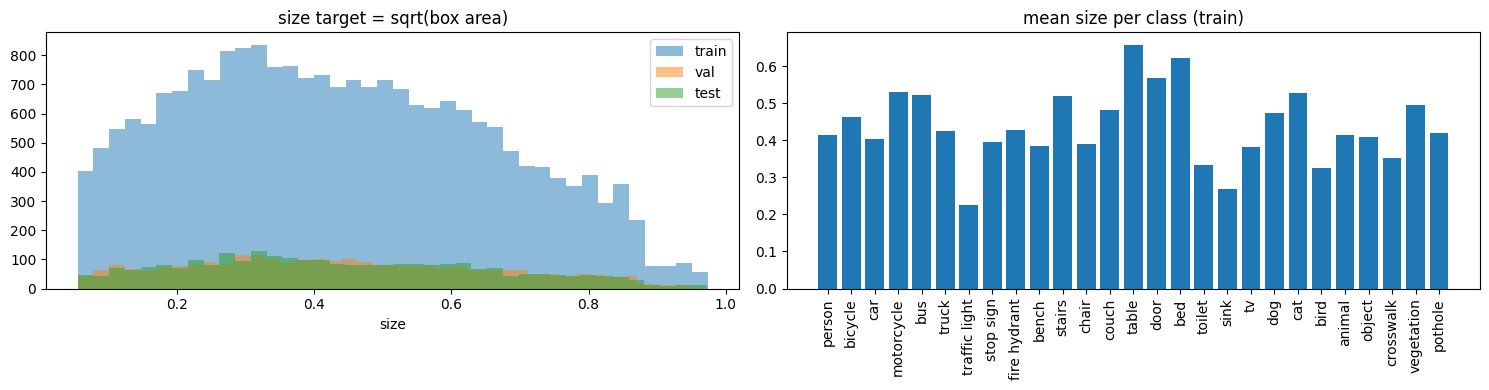

In [ ]:
# CELL 4 - INDEX: list every image with its class (from the folder) and its size target (from the label file). No cache files, so nothing can go stale.
def size_target(txt_path, cid):   # label file -> apparent size of the main object = sqrt(area) of its largest box
    best_cls = best_any = 0.0   # largest box area of this class / of any class
    for line in Path(txt_path).read_text().splitlines():   # each box line: class cx cy w h
        v = line.split()   # split into fields
        area = float(v[3]) * float(v[4])   # box area as a fraction of the picture
        best_any = max(best_any, area)   # track the largest box overall
        if int(v[0]) == cid:   # a box of the folder's own class
            best_cls = max(best_cls, area)   # track the largest of those
    return math.sqrt(best_cls if best_cls > 0 else best_any)   # use the class box (fallback: the largest box)

def build_index(split):   # all images of one split
    paths, labels, sizes = [], [], []   # parallel lists
    for cid, cname in enumerate(CLASS_LIST):   # every class folder
        for jp in sorted((Path(DATA) / split / folder_name(cname)).glob('*.jpg')):   # every image in it
            paths.append(str(jp))   # image path
            labels.append(cid)   # class id = the folder
            sizes.append(size_target(jp.with_suffix('.txt'), cid))   # size target from its label file
    return np.array(paths), np.array(labels, dtype=np.int32), np.array(sizes, dtype=np.float32)   # as arrays

INDEX = {s: build_index(s) for s in ('train', 'val', 'test')}   # index of all three splits
for s in INDEX:   # print a summary per split
    p, l, z = INDEX[s]   # its arrays
    print(f'{s:5s} {len(p):6d} images | size target mean {z.mean():.3f}  min {z.min():.3f}  max {z.max():.3f}')   # counts and size range

mean_size = [INDEX['train'][2][INDEX['train'][1] == c].mean() for c in range(NC)]   # mean apparent size per class
fig, ax = plt.subplots(1, 2, figsize=(15, 4))   # two charts side by side
for s in INDEX:   # one histogram per split
    ax[0].hist(INDEX[s][2], bins=40, alpha=0.5, label=s)   # distribution of size targets
ax[0].set_title('size target = sqrt(box area)'); ax[0].set_xlabel('size'); ax[0].legend()   # title, axis label, legend
ax[1].bar(range(NC), mean_size)   # mean size of each class
ax[1].set_xticks(range(NC)); ax[1].set_xticklabels(CLASS_LIST, rotation=90); ax[1].set_title('mean size per class (train)')   # class names under the bars
plt.tight_layout(); plt.show()   # draw both charts


In [ ]:
# CELL 5 - INPUT PIPELINE (tf.data): reads images from local disk in batches, colour-jitters the training images and scales pixels to -1..1.
# No zoom / crop augmentation on purpose: it would change how big the object looks and so corrupt the size (distance) target.
def read_image(path):   # file path -> uint8 RGB image of IMG_SIZE x IMG_SIZE
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)   # read and decode the JPEG as RGB
    if SRC_SIZE != IMG_SIZE:   # only when the model input differs from the stored size
        img = tf.cast(tf.image.resize(img, [IMG_SIZE, IMG_SIZE]), tf.uint8)   # resize the whole square picture (boxes are fractions, so they stay valid)
    return img   # the image

def to_input(x01):   # picture scaled 0..1 -> -1..1 (what MobileNetV2 expects); the same rule is used on the device
    return x01 * 2.0 - 1.0   # linear rescale

def augment(x01):   # random colour changes and a mirror flip (none of them change object size)
    x01 = tf.image.random_brightness(x01, 0.25)   # lighter or darker
    x01 = tf.image.random_contrast(x01, 0.7, 1.3)   # more or less contrast
    x01 = tf.image.random_saturation(x01, 0.7, 1.3)   # more or less colourful
    x01 = tf.image.random_hue(x01, 0.05)   # slight colour shift
    x01 = tf.image.random_flip_left_right(x01)   # mirror (left/right does not matter for the class or the size)
    return tf.clip_by_value(x01, 0.0, 1.0)   # keep pixel values inside 0..1

def make_example(path, label, size, train):   # one (path, label, size) -> (model input, targets)
    x = tf.cast(read_image(path), tf.float32) / 255.0   # pixels 0..1
    if train:   # augmentation only for training images
        x = augment(x)   # random changes
    return to_input(x), {'cls': tf.one_hot(label, NC), 'size': tf.reshape(size, [1])}   # image, one-hot class, size target

def make_ds(split, train):   # a batched tf.data pipeline for one split
    paths, labels, sizes = INDEX[split]   # the index arrays from cell 4
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, sizes))   # one element per image
    if train:   # shuffle only the training data
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)   # new order every epoch (only file names are held in memory)
    ds = ds.map(lambda p, l, s: make_example(p, l, s, train), num_parallel_calls=tf.data.AUTOTUNE)   # decode + augment in parallel
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)   # batches, prepared ahead of the GPU

train_ds, val_ds, test_ds = make_ds('train', True), make_ds('val', False), make_ds('test', False)   # the three pipelines
x_demo, y_demo = next(iter(train_ds))   # look at one batch
print('batch:', x_demo.shape, 'pixel range', float(tf.reduce_min(x_demo)), 'to', float(tf.reduce_max(x_demo)), '| targets:', {k: v.shape for k, v in y_demo.items()})   # shapes and range


batch: (32, 320, 320, 3) pixel range -1.0 to 1.0 | targets: {'cls': TensorShape([32, 27]), 'size': TensorShape([32, 1])}


## Part C - Model and training (GPU)
MobileNetV2 backbone with three SSDLite-style heads, two outputs (class logits, size). Phase 1 trains the new layers with the backbone frozen; phase 2 fine-tunes everything with a tiny learning rate.

In [ ]:
# CELL 6 - MODEL: MobileNetV2 backbone + three SSDLite-style heads (40x40, 20x20, 10x10 features) -> two outputs: class logits and object size.
FEATURE_LAYERS = ['block_6_expand_relu', 'block_13_expand_relu', 'out_relu']   # backbone layers at three scales (fine, medium, coarse)

def head(x, name):   # one SSDLite-style head: depthwise 3x3 + pointwise 1x1, then average over the picture
    x = keras.layers.DepthwiseConv2D(3, padding='same', use_bias=False, name=f'{name}_dw')(x)   # cheap spatial filter
    x = keras.layers.BatchNormalization(name=f'{name}_dw_bn')(x)   # normalise (folds into the conv when quantized)
    x = keras.layers.ReLU(6.0, name=f'{name}_dw_relu')(x)   # ReLU6 is friendly to int8
    x = keras.layers.Conv2D(256, 1, use_bias=False, name=f'{name}_pw')(x)   # mix channels down to 256
    x = keras.layers.BatchNormalization(name=f'{name}_pw_bn')(x)   # normalise
    x = keras.layers.ReLU(6.0, name=f'{name}_pw_relu')(x)   # ReLU6 again
    return keras.layers.GlobalAveragePooling2D(name=f'{name}_gap')(x)   # one 256-number summary per head

def build_model(alpha=ALPHA, weights=WEIGHTS):   # build the whole network as ONE flat graph (needed for quantization-aware training and pruning)
    inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')   # input: pictures already scaled to -1..1
    base = keras.applications.MobileNetV2(input_tensor=inp, include_top=False, weights=weights, alpha=alpha)   # the backbone
    for layer in base.layers:   # start with the backbone frozen
        layer.trainable = False   # (phase 1 trains only the new layers)
    pooled = [head(base.get_layer(n).output, t) for n, t in zip(FEATURE_LAYERS, ('small', 'med', 'large'))]   # three heads on three scales
    x = keras.layers.Concatenate(name='merge')(pooled)   # join the three summaries
    x = keras.layers.Dense(512, use_bias=False, name='fc1')(x)   # first fully connected layer
    x = keras.layers.BatchNormalization(name='fc1_bn')(x)   # normalise
    x = keras.layers.ReLU(6.0, name='fc1_relu')(x)   # ReLU6
    x = keras.layers.Dropout(0.4, name='fc1_drop')(x)   # drop 40 percent while training (less over-fitting)
    x = keras.layers.Dense(256, use_bias=False, name='fc2')(x)   # second fully connected layer
    x = keras.layers.BatchNormalization(name='fc2_bn')(x)   # normalise
    x = keras.layers.ReLU(6.0, name='fc2_relu')(x)   # ReLU6
    x = keras.layers.Dropout(0.3, name='fc2_drop')(x)   # drop 30 percent while training
    cls = keras.layers.Dense(NC, name='cls')(x)   # output 1: one score (logit) per class
    s = keras.layers.Dense(64, name='size_fc')(x)   # small branch for the size output
    s = keras.layers.ReLU(6.0, name='size_relu')(s)   # ReLU6
    size = keras.layers.Dense(1, activation='sigmoid', name='size')(s)   # output 2: apparent size between 0 and 1
    model = keras.Model(inp, [cls, size], name='fyp_navigation')   # the full model
    bb_bn = [l.name for l in base.layers if isinstance(l, keras.layers.BatchNormalization)]   # names of the backbone's batch-norm layers
    return model, bb_bn   # model and those names

def compile_model(m, lr):   # attach optimizer, losses and metrics
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=CLIPNORM),   # Adam with gradient clipping
              loss={'cls': keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=LABEL_SMOOTH),   # class loss
                    'size': keras.losses.Huber(delta=0.1)},   # size loss (robust to a few wrong boxes)
              loss_weights={'cls': 1.0, 'size': SIZE_LOSS_W},   # how much each loss counts
              metrics={'cls': [keras.metrics.CategoricalAccuracy(name='acc')],   # class accuracy
                       'size': [keras.metrics.MeanAbsoluteError(name='mae')]})   # size error

model, BACKBONE_BN = build_model()   # build it
compile_model(model, LR_HEAD)   # compile for phase 1
n_params = model.count_params()   # total number of weights
n_train = sum(int(np.prod(w.shape)) for w in model.trainable_weights)   # weights trained in phase 1
print(f'parameters: {n_params:,} total, {n_train:,} trainable now | float32 ~{n_params * 4 / 1e6:.1f} MB, int8 ~{n_params / 1e6:.1f} MB')   # size estimate


9406464/9406464 [==============================] - 2s 0us/step
parameters: 3,362,780 total, 1,097,628 trainable now | float32 ~13.5 MB, int8 ~3.4 MB


In [ ]:
# CELL 7 - TRAINING PHASE 1: train only the new heads while the pretrained backbone stays frozen (this runs on the GPU).
def callbacks_for(ckpt, lr_patience):   # early stopping, learning-rate reduction and best-weights saving
    return [keras.callbacks.EarlyStopping(monitor='val_cls_acc', mode='max', patience=8, restore_best_weights=True),   # stop when val accuracy stops improving
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=lr_patience, min_lr=1e-8, verbose=1),   # halve the learning rate when val loss stalls
            keras.callbacks.ModelCheckpoint(ckpt, monitor='val_cls_acc', mode='max', save_best_only=True, save_weights_only=True, verbose=0)]   # keep the best weights on disk

t0 = time.time()   # start the clock
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks_for(f'{OUT}/phase1_best.weights.h5', 4), verbose=2)   # train
model.load_weights(f'{OUT}/phase1_best.weights.h5')   # go back to the best epoch
r1 = model.evaluate(val_ds, verbose=0, return_dict=True)   # validation scores of the best epoch
print(f"phase 1 done in {(time.time() - t0) / 60:.1f} min | val class accuracy {r1['cls_acc']:.4f} | val size error {r1['size_mae']:.4f}")   # result


Epoch 1/20
675/675 - 87s - loss: 1.8869 - cls_loss: 1.7763 - size_loss: 0.0111 - cls_acc: 0.5537 - size_mae: 0.1536 - val_loss: 1.3690 - val_cls_loss: 1.2818 - val_size_loss: 0.0087 - val_cls_acc: 0.7011 - val_size_mae: 0.1291 - lr: 3.0000e-04 - 87s/epoch - 129ms/step
Epoch 2/20
675/675 - 77s - loss: 1.3920 - cls_loss: 1.3019 - size_loss: 0.0090 - cls_acc: 0.6984 - size_mae: 0.1319 - val_loss: 1.2380 - val_cls_loss: 1.1633 - val_size_loss: 0.0075 - val_cls_acc: 0.7400 - val_size_mae: 0.1153 - lr: 3.0000e-04 - 77s/epoch - 114ms/step
Epoch 3/20
675/675 - 76s - loss: 1.2741 - cls_loss: 1.1918 - size_loss: 0.0082 - cls_acc: 0.7301 - size_mae: 0.1235 - val_loss: 1.1907 - val_cls_loss: 1.1189 - val_size_loss: 0.0072 - val_cls_acc: 0.7496 - val_size_mae: 0.1120 - lr: 3.0000e-04 - 76s/epoch - 113ms/step
Epoch 4/20
675/675 - 76s - loss: 1.1941 - cls_loss: 1.1167 - size_loss: 0.0077 - cls_acc: 0.7549 - size_mae: 0.1180 - val_loss: 1.1539 - val_cls_loss: 1.0886 - val_size_loss: 0.0065 - val_cls_a

Epoch 1/40
675/675 - 238s - loss: 0.9651 - cls_loss: 0.8972 - size_loss: 0.0068 - cls_acc: 0.8285 - size_mae: 0.1076 - val_loss: 1.0943 - val_cls_loss: 1.0367 - val_size_loss: 0.0058 - val_cls_acc: 0.7741 - val_size_mae: 0.0957 - lr: 1.0000e-05 - 238s/epoch - 353ms/step
Epoch 2/40
675/675 - 220s - loss: 0.9199 - cls_loss: 0.8524 - size_loss: 0.0067 - cls_acc: 0.8447 - size_mae: 0.1071 - val_loss: 1.0883 - val_cls_loss: 1.0298 - val_size_loss: 0.0058 - val_cls_acc: 0.7748 - val_size_mae: 0.0971 - lr: 1.0000e-05 - 220s/epoch - 326ms/step
Epoch 3/40
675/675 - 219s - loss: 0.8814 - cls_loss: 0.8156 - size_loss: 0.0066 - cls_acc: 0.8547 - size_mae: 0.1052 - val_loss: 1.0982 - val_cls_loss: 1.0393 - val_size_loss: 0.0059 - val_cls_acc: 0.7696 - val_size_mae: 0.0972 - lr: 1.0000e-05 - 219s/epoch - 325ms/step
Epoch 4/40
675/675 - 220s - loss: 0.8609 - cls_loss: 0.7952 - size_loss: 0.0066 - cls_acc: 0.8653 - size_mae: 0.1052 - val_loss: 1.0830 - val_cls_loss: 1.0257 - val_size_loss: 0.0057 - va

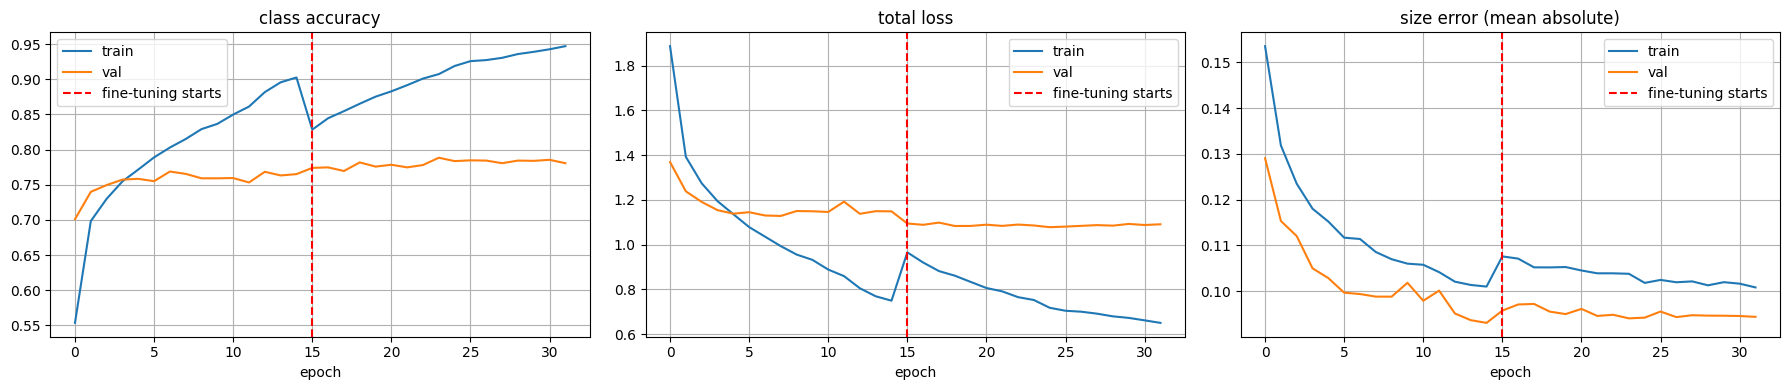

In [ ]:
# CELL 8 - TRAINING PHASE 2: unfreeze the whole network and fine-tune with a very small learning rate; then plot the curves and save the float model.
for layer in model.layers:   # every layer
    layer.trainable = True   # unfreeze
for layer in model.layers:   # then
    if layer.name in BACKBONE_BN:   # keep the backbone's batch-norm layers frozen
        layer.trainable = False   # (steadier fine-tuning and better int8 behaviour)
compile_model(model, LR_FINE)   # re-compile so the change takes effect
t0 = time.time()   # start the clock
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE, callbacks=callbacks_for(f'{OUT}/best.weights.h5', 5), verbose=2)   # fine-tune
model.load_weights(f'{OUT}/best.weights.h5')   # go back to the best epoch
r2 = model.evaluate(val_ds, verbose=0, return_dict=True)   # validation scores of the best epoch
print(f"phase 2 done in {(time.time() - t0) / 60:.1f} min | val class accuracy {r2['cls_acc']:.4f} | val size error {r2['size_mae']:.4f}")   # result
model.save(f'{OUT}/float_model.keras')   # save the full float model
model.save_weights(f'{OUT}/float.weights.h5')   # and just its weights

h1, h2 = hist1.history, hist2.history   # the two training logs
cut = len(h1['loss'])   # epoch where fine-tuning starts
fig, ax = plt.subplots(1, 3, figsize=(18, 4))   # three charts
ax[0].plot(h1['cls_acc'] + h2['cls_acc'], label='train'); ax[0].plot(h1['val_cls_acc'] + h2['val_cls_acc'], label='val')   # class accuracy
ax[0].set_title('class accuracy')   # chart title
ax[1].plot(h1['loss'] + h2['loss'], label='train'); ax[1].plot(h1['val_loss'] + h2['val_loss'], label='val')   # total loss
ax[1].set_title('total loss')   # chart title
ax[2].plot(h1['size_mae'] + h2['size_mae'], label='train'); ax[2].plot(h1['val_size_mae'] + h2['val_size_mae'], label='val')   # size error
ax[2].set_title('size error (mean absolute)')   # chart title
for a in ax:   # decorate all three
    a.axvline(cut, color='red', linestyle='--', label='fine-tuning starts'); a.set_xlabel('epoch'); a.grid(True); a.legend()   # phase marker, label, grid, legend
plt.tight_layout(); plt.savefig(f'{OUT}/training_curves.png', dpi=130); plt.show()   # save and show


## Part D - Evaluation of the float model
Class accuracy, size/distance error, distance-band accuracy and the confidence table that justifies `CONF_MIN`. These tools are reused for every compressed model below.

In [ ]:
# CELL 9 - EVALUATION TOOLS + FLOAT MODEL RESULTS: class accuracy, per-class accuracy, size/distance error, distance-band accuracy and the confidence table.
def predict_float(m, split):   # run a Keras model over one split
    out = m.predict(make_ds(split, False), verbose=0)   # [class logits, sizes]
    return out[0], out[1][:, 0]   # logits (N x 27) and sizes (N)

def evaluate_predictions(name, logits, sizes, split, verbose=True):   # all metrics for one model on one split
    _, labels, size_true = INDEX[split]   # ground truth
    pred = logits.argmax(1)   # predicted class
    acc = float((pred == labels).mean())   # overall accuracy
    size_mae = float(np.abs(sizes - size_true).mean())   # mean absolute size error
    tb = np.array([band_of(metres_from_size(c, z)) for c, z in zip(labels, size_true)])   # true distance band (from the annotated box)
    pb = np.array([band_of(metres_from_size(c, z)) for c, z in zip(labels, sizes)])   # predicted distance band (true class, predicted size)
    band_acc = float((tb == pb).mean())   # exact band match
    within1 = float((np.abs(tb - pb) <= 1).mean())   # off by at most one band
    near_true = tb <= 1   # truly closer than 2 m
    missed = float(((pb >= 2) & near_true).sum() / max(near_true.sum(), 1))   # share of those reported as 2 m or farther (dangerous mistakes)
    res = dict(name=name, split=split, acc=acc, size_mae=size_mae, band_acc=band_acc, within1=within1, missed_near=missed)   # the summary
    if verbose:   # print the details
        print(f'--- {name} on {split} ---')   # title
        print(f'class accuracy {acc:.4f} | size error {size_mae:.4f} | band exact {band_acc:.3f} | band within 1 {within1:.3f} | near objects reported as far {missed:.3f}')   # headline numbers
        per = [(CLASS_LIST[c], float((pred[labels == c] == c).mean())) for c in range(NC)]   # accuracy per class
        print('per class:', '  '.join(f'{n}={a:.2f}' for n, a in sorted(per, key=lambda t: t[1])))   # worst classes first
        cm = np.zeros((4, 4), int)   # band confusion matrix
        for a, b in zip(tb, pb):   # every image
            cm[a, b] += 1   # count (true band, predicted band)
        print('band confusion (rows = true, columns = predicted: very close / close / near / far):')   # explanation
        print(cm)   # the matrix
        conf = np.array([softmax(z).max() for z in logits])   # confidence of each prediction
        print('confidence rule (below the threshold the item is announced as a generic object):')   # explanation
        for t in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8):   # candidate thresholds
            keep = conf >= t   # images the model names confidently
            print(f'  threshold {t:.1f}: named confidently {keep.mean():.3f} of images | accuracy of those {float((pred[keep] == labels[keep]).mean()) if keep.any() else 0:.3f} | sent to "object": {1 - keep.mean():.3f}')   # coverage vs accuracy
    return res   # the summary

lg, sz = predict_float(model, 'val')   # float model on the validation split
float_val = evaluate_predictions('float Keras model', lg, sz, 'val')   # evaluate and print


--- float Keras model on val ---
class accuracy 0.7885 | size error 0.0941 | band exact 0.712 | band within 1 0.975 | near objects reported as far 0.094
per class: chair=0.48  object=0.49  couch=0.58  car=0.61  truck=0.62  person=0.64  bed=0.74  toilet=0.75  bench=0.76  cat=0.76  tv=0.78  dog=0.78  bicycle=0.79  table=0.80  bus=0.82  sink=0.82  traffic light=0.84  vegetation=0.85  motorcycle=0.88  stairs=0.88  bird=0.89  animal=0.91  stop sign=0.94  fire hydrant=0.94  door=0.97  crosswalk=0.98  pothole=0.99
band confusion (rows = true, columns = predicted: very close / close / near / far):
[[539 135  17   1]
 [107 702 133   2]
 [ 14 196 412  45]
 [  0  33  94 270]]
confidence rule (below the threshold the item is announced as a generic object):
  threshold 0.3: named confidently 0.970 of images | accuracy of those 0.804 | sent to "object": 0.030
  threshold 0.4: named confidently 0.917 of images | accuracy of those 0.827 | sent to "object": 0.083
  threshold 0.5: named confidently 0.84

train accuracy 0.964 | val accuracy 0.789  (a large gap means overfitting)

per class: train acc -> val acc (gap)
  chair          0.87 -> 0.48 (+0.39)
  object         0.93 -> 0.49 (+0.44)
  couch          0.94 -> 0.58 (+0.36)
  car            0.92 -> 0.61 (+0.31)
  truck          0.93 -> 0.62 (+0.31)
  person         0.95 -> 0.64 (+0.31)
  bed            0.95 -> 0.74 (+0.21)
  toilet         0.94 -> 0.75 (+0.19)
  bench          0.98 -> 0.76 (+0.22)
  cat            0.98 -> 0.76 (+0.22)

most confused pairs on val (true -> predicted : count):
  toilet         -> sink             20
  chair          -> couch            17
  truck          -> car              17
  couch          -> chair            14
  bed            -> couch            13
  sink           -> toilet           10
  couch          -> bed               9
  bicycle        -> motorcycle        9
  car            -> bus               8
  person         -> table             8
  object         -> vegetation        7
  table  

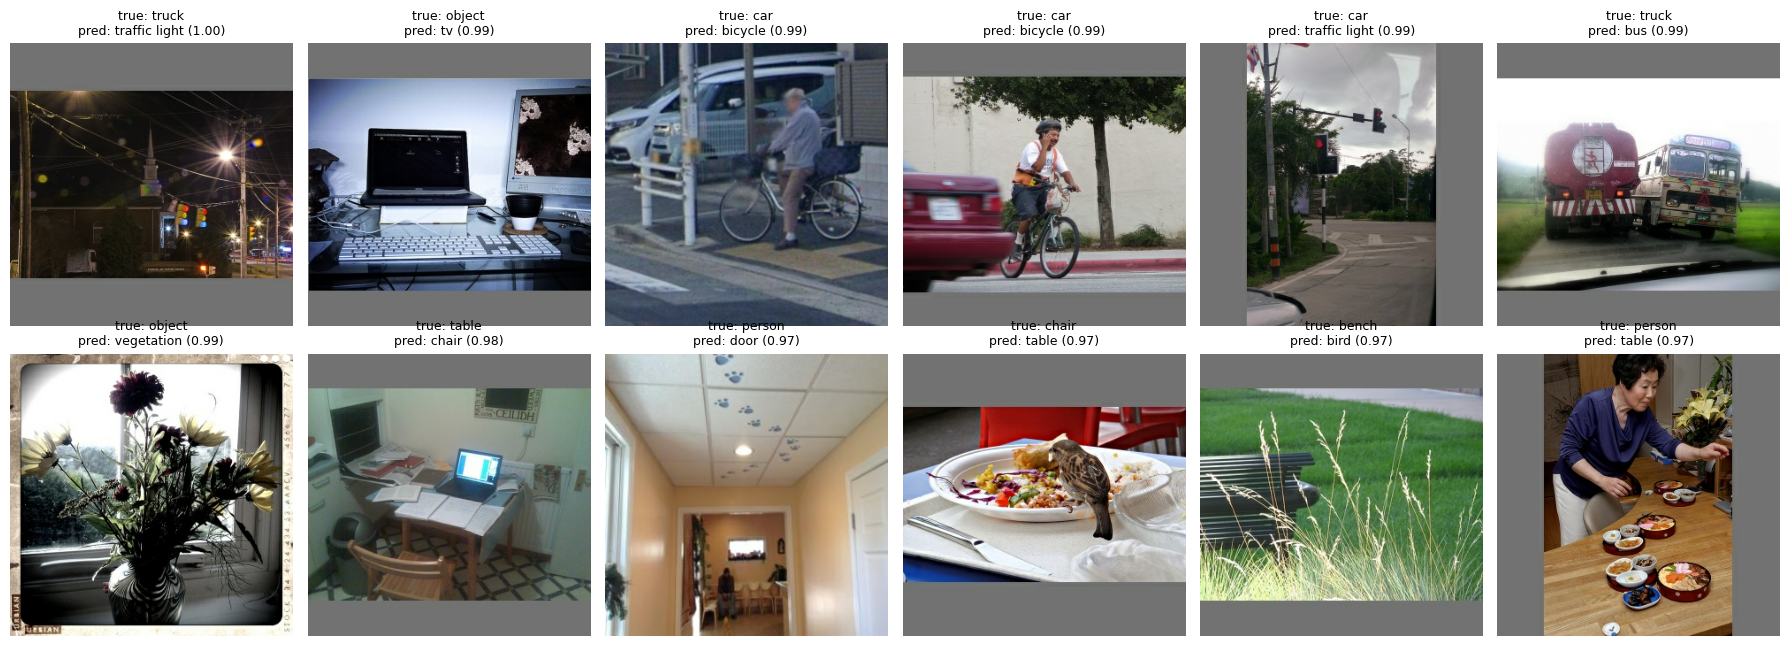

In [ ]:
# EXTRA CELL - DIAGNOSIS (run after cell 9, needs the trained `model`): why is accuracy where it is? overfitting gap, most confused pairs, size/distance bias, and the confident mistakes.
lg_tr, sz_tr = predict_float(model, 'train')   # float model on ALL training images (no augmentation) to compare with validation
_, y_tr, s_tr = INDEX['train']   # training labels and size targets
_, y_va, s_va = INDEX['val']   # validation labels and size targets
p_tr, p_va = lg_tr.argmax(1), lg.argmax(1)   # predicted classes (lg = validation logits from cell 9)
print(f'train accuracy {float((p_tr == y_tr).mean()):.3f} | val accuracy {float((p_va == y_va).mean()):.3f}  (a large gap means overfitting)')   # overall gap

print('\nper class: train acc -> val acc (gap)')   # section title
rows = []   # one row per class
for c in range(NC):   # every class
    a_tr = float((p_tr[y_tr == c] == c).mean()); a_va = float((p_va[y_va == c] == c).mean())   # accuracy on train and val
    rows.append((a_va, CLASS_LIST[c], a_tr))   # remember it
for a_va, n, a_tr in sorted(rows)[:10]:   # the ten weakest classes
    print(f'  {n:14s} {a_tr:.2f} -> {a_va:.2f} ({a_tr - a_va:+.2f})')   # one line each

print('\nmost confused pairs on val (true -> predicted : count):')   # section title
cm = np.zeros((NC, NC), int)   # class confusion matrix
for t, p in zip(y_va, p_va):   # every validation image
    cm[t, p] += 1   # count (true, predicted)
np.fill_diagonal(cm, 0)   # ignore the correct answers
for k in np.argsort(cm.ravel())[::-1][:15]:   # the 15 biggest off-diagonal cells
    t, p = divmod(int(k), NC)   # back to (true, predicted)
    print(f'  {CLASS_LIST[t]:14s} -> {CLASS_LIST[p]:14s} {cm[t, p]:4d}')   # one line each

print('\nsize head on val (target = sqrt of the largest box area, 0-1):')   # section title
err = sz - s_va   # signed error (positive = the model thinks the object is bigger / closer)
print(f'  mean error {err.mean():+.4f} | MAE {np.abs(err).mean():.4f} | train MAE {float(np.abs(sz_tr - s_tr).mean()):.4f}')   # bias and error, train vs val
for lo, hi in ((0, .2), (.2, .4), (.4, .6), (.6, .8), (.8, 1.01)):   # five size ranges
    m = (s_va >= lo) & (s_va < hi)   # images in this range
    if m.any():   # skip empty ranges
        print(f'  true size {lo:.1f}-{min(hi, 1):.1f}: {int(m.sum()):4d} images | MAE {np.abs(err[m]).mean():.3f} | bias {err[m].mean():+.3f}')   # error per range
print('  worst classes for distance (size MAE):', '  '.join(f'{CLASS_LIST[c]}={np.abs(err[y_va == c]).mean():.3f}' for c in np.argsort([-np.abs(err[y_va == c]).mean() for c in range(NC)])[:6]))   # classes with the largest size error

conf_va = np.array([softmax(z).max() for z in lg])   # confidence of every validation prediction
wrong = np.where((p_va != y_va) & (conf_va >= 0.7))[0]   # wrong answers the model was sure about
print(f'\nconfident mistakes (confidence >= 0.7 but wrong): {len(wrong)} of {len(y_va)} val images')   # how many
pick = wrong[np.argsort(-conf_va[wrong])][:12]   # the 12 most confident mistakes
fig, axs = plt.subplots(2, 6, figsize=(18, 6.5))   # a 2 x 6 grid
for ax, i in zip(axs.ravel(), pick):   # one picture per axis
    ax.imshow(read_image(INDEX['val'][0][i]).numpy())   # the picture
    ax.set_title(f'true: {CLASS_LIST[y_va[i]]}\npred: {CLASS_LIST[p_va[i]]} ({conf_va[i]:.2f})', fontsize=9)   # label vs prediction
    ax.axis('off')   # no axes
plt.tight_layout(); plt.show()   # show the grid

## Part E - Compression: quantization first, pruning only if needed

### Int8 quantization (main step)
Full-integer post-training quantization with 297 calibration images. The `.tflite` takes an int8 image and returns int8 results, as a microcontroller expects.

In [ ]:
# CELL 10 - INT8 QUANTIZATION (the main compression step): post-training full-integer conversion using ~300 calibration images.
def load_np(path):   # one image file -> float32 array scaled -1..1, exactly as in training (RGB, not BGR)
    x = tf.io.decode_jpeg(tf.io.read_file(str(path)), channels=3)   # read and decode as RGB
    if SRC_SIZE != IMG_SIZE:   # only when the model input differs from the stored size
        x = tf.cast(tf.image.resize(x, [IMG_SIZE, IMG_SIZE]), tf.uint8)   # resize the square picture
    return x.numpy().astype(np.float32) / 255.0 * 2.0 - 1.0   # scale to -1..1

rng = random.Random(SEED)   # repeatable random choice
tr_paths, tr_labels, _ = INDEX['train']   # training index
calib_paths = []   # calibration images, the same number from every class
for c in range(NC):   # every class
    ids = list(np.where(tr_labels == c)[0])   # its training images
    calib_paths += [tr_paths[i] for i in rng.sample(ids, min(CALIB_PER_CLASS, len(ids)))]   # random few of them
print('calibration images:', len(calib_paths))   # how many

def representative_dataset():   # the converter calls this to learn the value range of every layer
    for p in calib_paths:   # each calibration image
        yield [load_np(p)[None]]   # one batch of one image

def to_int8_tflite(m, representative=True):   # Keras model -> fully-integer TFLite bytes
    conv = tf.lite.TFLiteConverter.from_keras_model(m)   # converter for this model
    conv.optimizations = [tf.lite.Optimize.DEFAULT]   # enable quantization
    if representative:   # post-training quantization needs example data
        conv.representative_dataset = representative_dataset   # give it the calibration images
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]   # allow integer operations only
    conv.inference_input_type = tf.int8   # the camera image goes in as int8
    conv.inference_output_type = tf.int8   # results come out as int8
    return conv.convert()   # run the conversion

def gzip_size(b):   # compressed size in bytes (the MNIST notebook reports this too)
    return len(zlib.compress(b, 9))   # deflate at the highest level

def float_share(b):   # share of tensor memory that is still floating point (about 0 for a fully-integer model)
    ip = tf.lite.Interpreter(model_content=b)   # open the model
    ip.allocate_tensors()   # prepare its tensors
    tot = flt = 0   # all bytes / float bytes
    for t in ip.get_tensor_details():   # every tensor in the model
        n = int(np.prod(t['shape'])) * np.dtype(t['dtype']).itemsize   # its size in bytes
        tot += n   # add to the total
        flt += n if t['dtype'] == np.float32 else 0   # add to the float total when it is float32
    return flt / max(tot, 1)   # fraction that is float

SIZES = {}   # name -> (raw bytes, compressed bytes)
float_tflite = tf.lite.TFLiteConverter.from_keras_model(model).convert()   # un-quantized TFLite, only for the size comparison
SIZES['float32 TFLite'] = (len(float_tflite), gzip_size(float_tflite))   # remember its sizes
try:   # full-integer conversion can fail on unsupported layers
    ptq_bytes = to_int8_tflite(model)   # the int8 model
    print('full-integer quantization worked')   # success message
except Exception as e:   # fall back to the weaker dynamic-range quantization
    print('full-integer failed:', str(e)[:200], '\nfalling back to dynamic-range quantization')   # explain
    conv = tf.lite.TFLiteConverter.from_keras_model(model)   # new converter
    conv.optimizations = [tf.lite.Optimize.DEFAULT]   # weights int8, activations float
    ptq_bytes = conv.convert()   # convert
SIZES['int8 PTQ'] = (len(ptq_bytes), gzip_size(ptq_bytes))   # remember its sizes
open(f'{OUT}/model_int8_ptq.tflite', 'wb').write(ptq_bytes)   # save the file
for k, (raw, gz) in SIZES.items():   # print the size table
    print(f'{k:16s} {raw / 1e6:6.2f} MB raw | {gz / 1e6:6.2f} MB compressed')   # sizes


calibration images: 297


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


full-integer quantization worked
float32 TFLite    13.24 MB raw |  12.27 MB compressed
int8 PTQ           3.91 MB raw |   3.29 MB compressed


In [ ]:
# CELL 11 - EVALUATE THE TFLITE MODEL: run the real int8 file image by image (as the device would) and compare with the float model.
def dequant(arr, d):   # integer tensor -> real numbers using the tensor's scale and zero point
    scale, zp = d['quantization']   # quantization parameters
    return arr.astype(np.float32) if scale == 0 else (arr.astype(np.float32) - zp) * scale   # real = (q - zero_point) * scale

def run_tflite(tfl, paths):   # list of image files -> (class logits, sizes) from a TFLite model
    it = tf.lite.Interpreter(model_content=tfl, num_threads=2)   # the TFLite interpreter
    it.allocate_tensors()   # prepare its memory
    inp = it.get_input_details()[0]   # the input tensor
    outs = it.get_output_details()   # the output tensors
    cls_d = next(o for o in outs if o['shape'][-1] == NC)   # the 27-number output is the class scores
    size_d = next(o for o in outs if o['shape'][-1] == 1)   # the 1-number output is the size
    scale, zp = inp['quantization']   # how to turn real input values into integers
    L, S = [], []   # collected logits and sizes
    for i, p in enumerate(paths):   # every image
        x = load_np(p)[None]   # float input -1..1
        if inp['dtype'] != np.float32:   # integer model
            info = np.iinfo(inp['dtype'])   # allowed integer range
            x = np.clip(np.round(x / scale + zp), info.min, info.max).astype(inp['dtype'])   # quantize the input
        it.set_tensor(inp['index'], x)   # feed the image
        it.invoke()   # run the network
        L.append(dequant(it.get_tensor(cls_d['index'])[0], cls_d))   # class scores as real numbers
        S.append(float(dequant(it.get_tensor(size_d['index'])[0], size_d)[0]))   # size as a real number
        if (i + 1) % 1000 == 0:   # progress
            print(f'  {i + 1}/{len(paths)} images')   # show it
    return np.array(L), np.array(S)   # arrays

def eval_tflite(name, tfl, split, verbose=True):   # evaluate a TFLite model on a whole split
    lg_, sz_ = run_tflite(tfl, INDEX[split][0])   # run it
    return evaluate_predictions(name, lg_, sz_, split, verbose)   # metrics

CANDIDATES = {}   # name -> {'bytes': model file, 'val': validation metrics}
t0 = time.time()   # start the clock
ptq_val = eval_tflite('int8 PTQ', ptq_bytes, 'val')   # evaluate the int8 model on validation data
CANDIDATES['int8 PTQ'] = dict(bytes=ptq_bytes, val=ptq_val)   # remember it
print(f'evaluation took {time.time() - t0:.0f} s')   # how long

def show_table():   # side-by-side comparison of everything built so far
    print(f"{'model':22s}{'val acc':>9s}{'size err':>10s}{'band acc':>10s}{'raw MB':>9s}{'zip MB':>9s}")   # header
    print(f"{'float Keras':22s}{float_val['acc']:9.4f}{float_val['size_mae']:10.4f}{float_val['band_acc']:10.3f}{'-':>9s}{'-':>9s}")   # baseline row
    for k, v in CANDIDATES.items():   # each compressed candidate
        raw, gz = SIZES[k]   # its sizes
        print(f"{k:22s}{v['val']['acc']:9.4f}{v['val']['size_mae']:10.4f}{v['val']['band_acc']:10.3f}{raw / 1e6:9.2f}{gz / 1e6:9.2f}")   # one row each
show_table()   # print it


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


  1000/2700 images
  2000/2700 images
--- int8 PTQ on val ---
class accuracy 0.7689 | size error 0.0953 | band exact 0.701 | band within 1 0.979 | near objects reported as far 0.109
per class: object=0.45  chair=0.49  couch=0.57  car=0.58  truck=0.63  bench=0.67  person=0.70  dog=0.72  cat=0.72  toilet=0.74  bed=0.75  tv=0.75  bus=0.76  bicycle=0.78  table=0.79  traffic light=0.82  motorcycle=0.83  sink=0.83  stairs=0.84  vegetation=0.85  bird=0.89  stop sign=0.90  fire hydrant=0.90  animal=0.90  door=0.96  crosswalk=0.96  pothole=0.98
band confusion (rows = true, columns = predicted: very close / close / near / far):
[[528 147  16   1]
 [102 681 159   2]
 [ 11 187 416  53]
 [  0  28 100 269]]
confidence rule (below the threshold the item is announced as a generic object):
  threshold 0.3: named confidently 0.968 of images | accuracy of those 0.787 | sent to "object": 0.032
  threshold 0.4: named confidently 0.915 of images | accuracy of those 0.810 | sent to "object": 0.085
  threshol

### Pruning (only if the int8 file is bigger than `TARGET_MB`)
Pruning zeroes small weights of the two big fully connected layers; it mainly helps the *compressed* size.

In [ ]:
# CELL 12 - PRUNING (only if needed): zeroes the smallest weights of the two big fully connected layers, fine-tunes, then re-quantizes.
# Note: pruning mainly shrinks the COMPRESSED file; the raw .tflite that sits in the device's flash keeps the same size.
size_mb = len(ptq_bytes) / 1e6   # size of the plain int8 file
need_prune = RUN_PRUNING is True or (RUN_PRUNING == 'auto' and size_mb > TARGET_MB)   # run when asked, or when the file is too big
print(f'int8 file {size_mb:.2f} MB (wanted <= {TARGET_MB} MB) -> pruning {"RUNS" if need_prune else "is skipped"}')   # decision
if need_prune:   # only then
    is_pruned = lambda l: type(l).__name__ == 'PruneLowMagnitude'   # True for the wrapper layer that holds a pruned layer
    steps = math.ceil(len(INDEX['train'][0]) / BATCH) * EPOCHS_PRUNE   # total training steps during pruning
    schedule = tfmot.sparsity.keras.PolynomialDecay(initial_sparsity=0.10, final_sparsity=PRUNE_FINAL_SPARSITY, begin_step=0, end_step=steps, frequency=max(1, min(100, steps // 20)))   # sparsity grows from 10 percent to the target; the mask is refreshed regularly
    def wrap(layer):   # decide per layer whether to prune it
        fresh = layer.__class__.from_config(layer.get_config())   # an independent copy (the original float model stays untouched)
        if isinstance(layer, keras.layers.Dense) and layer.name in ('fc1', 'fc2'):   # only the two big fully connected layers
            return tfmot.sparsity.keras.prune_low_magnitude(fresh, pruning_schedule=schedule)   # wrap it for pruning
        return fresh   # every other layer is copied as it is
    pm = keras.models.clone_model(model, clone_function=wrap)   # copy of the model with pruning wrappers
    for layer in pm.layers:   # copy the trained weights across, layer by layer
        inner = layer.layer if is_pruned(layer) else layer   # the real layer inside a wrapper
        inner.set_weights(model.get_layer(inner.name).get_weights())   # same name in the original model
    for layer in pm.layers:   # only the pruned layers keep training
        layer.trainable = is_pruned(layer)   # everything else is frozen
    pm.compile(optimizer=keras.optimizers.Adam(learning_rate=2e-5, clipnorm=CLIPNORM),   # small learning rate
               loss={'cls': keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=LABEL_SMOOTH), 'size': keras.losses.Huber(delta=0.1)},   # same losses
               loss_weights={'cls': 1.0, 'size': SIZE_LOSS_W},   # same weights
               metrics={'cls': [keras.metrics.CategoricalAccuracy(name='acc')], 'size': [keras.metrics.MeanAbsoluteError(name='mae')]})   # same metrics
    pm.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_PRUNE, callbacks=[tfmot.sparsity.keras.UpdatePruningStep()], verbose=2)   # fine-tune while the mask grows
    stripped = tfmot.sparsity.keras.strip_pruning(pm)   # remove the pruning wrappers, keep the zeros
    for n in ('fc1', 'fc2'):   # report what was achieved
        w = stripped.get_layer(n).get_weights()[0]   # that layer's weights
        print(f'{n}: {float((w == 0).mean()) * 100:.1f} percent of weights are zero')   # sparsity
    pr_bytes = to_int8_tflite(stripped)   # quantize the pruned model
    SIZES['int8 PTQ + pruned'] = (len(pr_bytes), gzip_size(pr_bytes))   # remember its sizes
    open(f'{OUT}/model_int8_pruned.tflite', 'wb').write(pr_bytes)   # save the file
    CANDIDATES['int8 PTQ + pruned'] = dict(bytes=pr_bytes, val=eval_tflite('int8 PTQ + pruned', pr_bytes, 'val', verbose=False))   # evaluate and remember
    show_table()   # updated comparison


int8 file 3.91 MB (wanted <= 4.0 MB) -> pruning is skipped


### Choose the final model
Only candidates that keep class accuracy and size accuracy within the limits and are fully integer can be chosen. The test split is used once, here.

In [ ]:
# CELL 13 - CHOOSE THE FINAL MODEL and measure it ONCE on the untouched test split.
FORCE_CHOICE = None   # type a candidate name (for example 'int8 PTQ') to override the automatic choice
ok = {k: v for k, v in CANDIDATES.items() if float_val['acc'] - v['val']['acc'] <= MAX_ACC_DROP and v['val']['size_mae'] - float_val['size_mae'] <= MAX_SIZE_RISE and float_share(v['bytes']) < 0.02}   # candidates that keep BOTH class accuracy and size (distance) accuracy AND are fully integer
for k, v in CANDIDATES.items():   # explain every candidate
    print(f"  {k:20s} accuracy change {(v['val']['acc'] - float_val['acc']) * 100:+.2f} points | size error change {v['val']['size_mae'] - float_val['size_mae']:+.4f} | float tensors {float_share(v['bytes']) * 100:.1f} percent | {'accepted' if k in ok else 'REJECTED'}")   # verdict per candidate
pool = ok if ok else CANDIDATES   # if none qualifies, choose among all
if not ok:   # nothing met the limits
    print('WARNING: no candidate met the limits, so the most accurate one is used. Try a larger CALIB_PER_CLASS, or look at the per-class results above.')   # tell the user
best = FORCE_CHOICE or max(pool, key=lambda k: (round(pool[k]['val']['acc'], 3), -SIZES[k][0]))   # highest val accuracy, then the smallest file
print('candidates within the accuracy limit:', list(ok) or 'none', '| chosen:', best)   # explain the choice
final_bytes = CANDIDATES[best]['bytes']   # the chosen model file
FINAL_TFLITE = f'{OUT}/fyp_navigation_v3.tflite'   # where it is saved
open(FINAL_TFLITE, 'wb').write(final_bytes)   # write it
it = tf.lite.Interpreter(model_content=final_bytes); it.allocate_tensors()   # open it to read its tensor details
IN = it.get_input_details()[0]   # input tensor details
IN_SCALE, IN_ZP = IN['quantization']   # how real input values map to integers
print(f"final model: {len(final_bytes) / 1e6:.2f} MB | input {IN['dtype'].__name__} {tuple(IN['shape'])}, scale {IN_SCALE:.6f}, zero point {IN_ZP}")   # facts the firmware needs
lg_f, sz_f = predict_float(model, 'test')   # float model on the test split
float_test = evaluate_predictions('float Keras model', lg_f, sz_f, 'test', verbose=False)   # its test metrics
final_test = eval_tflite(f'FINAL {best}', final_bytes, 'test')   # the final model on the test split (printed in full)
print(f"\nTEST class accuracy: float {float_test['acc']:.4f} -> final int8 {final_test['acc']:.4f} (change {(final_test['acc'] - float_test['acc']) * 100:+.2f} points)")   # headline comparison


  int8 PTQ             accuracy change -1.96 points | size error change +0.0012 | float tensors 0.0 percent | REJECTED
candidates within the accuracy limit: none | chosen: int8 PTQ
final model: 3.91 MB | input int8 (np.int32(1), np.int32(320), np.int32(320), np.int32(3)), scale 0.007843, zero point -1
  1000/2700 images
  2000/2700 images
--- FINAL int8 PTQ on test ---
class accuracy 0.7856 | size error 0.0938 | band exact 0.700 | band within 1 0.983 | near objects reported as far 0.112
per class: object=0.45  chair=0.51  car=0.57  couch=0.61  bench=0.64  tv=0.66  person=0.69  truck=0.72  bed=0.75  sink=0.75  table=0.76  toilet=0.76  cat=0.79  vegetation=0.79  dog=0.80  bus=0.83  animal=0.88  bird=0.89  bicycle=0.90  motorcycle=0.90  traffic light=0.90  stop sign=0.92  door=0.92  fire hydrant=0.94  stairs=0.95  pothole=0.96  crosswalk=0.97
band confusion (rows = true, columns = predicted: very close / close / near / far):
[[508 152  19   0]
 [103 690 160   5]
 [ 11 178 466  64]
 [  2  

## Part F - Alerts and speech
### Demo on test pictures
What the device would decide for 12 pictures: class, distance, priority and the sentence.

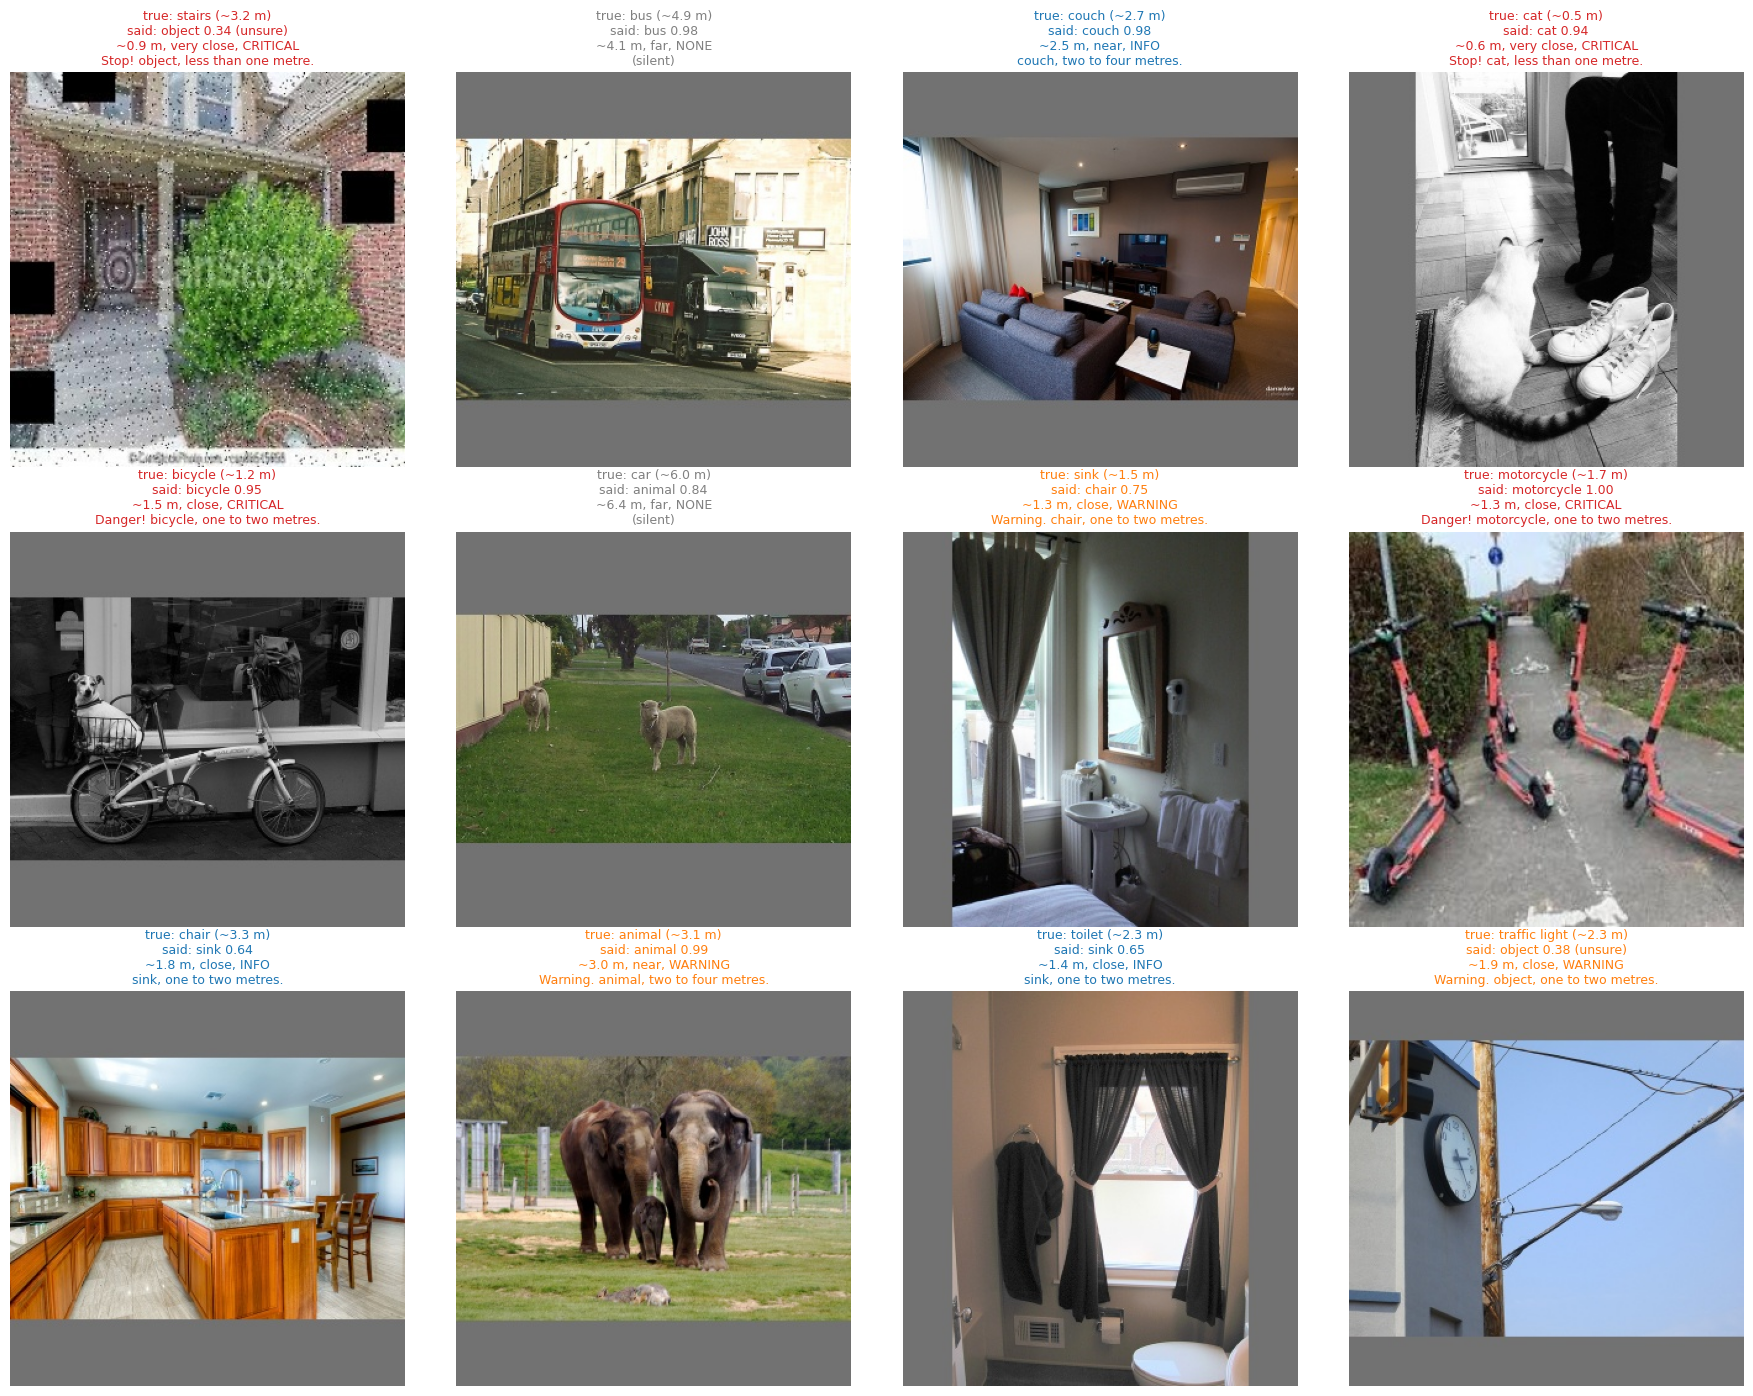

  1000/2700 images
  2000/2700 images
14.6 percent of test pictures fall below CONF_MIN=0.5 and would be announced as a generic "object"


In [ ]:
# CELL 14 - ALERT DEMO: run the final int8 model on test pictures and show the decision the device would make (class, distance, priority, sentence).
rng = random.Random(7)   # repeatable choice of demo pictures
t_paths, t_labels, t_sizes = INDEX['test']   # test index
pick = [rng.choice(list(np.where(t_labels == c)[0])) for c in rng.sample(range(NC), 12)]   # one picture from each of 12 random classes
lg_d, sz_d = run_tflite(final_bytes, [t_paths[i] for i in pick])   # run the final model on them
colors = {0: 'gray', 1: 'tab:blue', 2: 'tab:orange', 3: 'tab:red'}   # title colour per priority level
fig, axes = plt.subplots(3, 4, figsize=(18, 14))   # a 3 x 4 grid
for ax, i, lg1, sz1 in zip(axes.flatten(), pick, lg_d, sz_d):   # one panel per picture
    d = decide(lg1, sz1)   # the alert decision
    ax.imshow(plt.imread(t_paths[i]))   # the picture
    true_m = metres_from_size(int(t_labels[i]), t_sizes[i])   # distance implied by the annotated box
    ax.set_title(f"true: {CLASS_LIST[t_labels[i]]} (~{true_m:.1f} m)\nsaid: {d['name']} {d['conf']:.2f}{' (unsure)' if d['unsure'] else ''}\n"   # what it really is / what the model says
                 f"~{d['metres']:.1f} m, {BAND_NAMES[d['band']]}, {PRIORITY_NAMES[d['priority']].upper()}\n{d['text'] or '(silent)'}", fontsize=9, color=colors[d['priority']])   # distance, priority and spoken words
    ax.axis('off')   # hide the axes
plt.tight_layout(); plt.show()   # draw the grid
lg_all, sz_all = run_tflite(final_bytes, t_paths)   # whole test split, to count how often the generic-object rule fires
conf_all = np.array([softmax(z).max() for z in lg_all])   # confidence of every prediction
print(f'{(conf_all < CONF_MIN).mean() * 100:.1f} percent of test pictures fall below CONF_MIN={CONF_MIN} and would be announced as a generic "object"')   # how often


### Speech clips (hard-coded, not generated live)
Every (class, distance band) sentence is spoken once here by a text-to-speech service and saved as a WAV file, with an alert tone in front (3 high beeps = critical, 2 = warning, 1 soft = info). The device only plays files. Needs internet in this notebook only.

In [ ]:
# CELL 15 - SPEECH CLIPS: every sentence is spoken ONCE here by a text-to-speech engine and stored as a WAV file, so the device only plays files (no live speech synthesis).
from gtts import gTTS   # Google text-to-speech (needs internet, used only in this notebook)
from IPython.display import Audio, display   # play clips inside the notebook
AUDIO_DIR = Path(OUT) / 'audio'   # clips are written here
AUDIO_DIR.mkdir(exist_ok=True)   # create the folder

def tone(freq, seconds, vol=0.5):   # a short beep as 16-bit samples
    t = np.arange(int(AUDIO_RATE * seconds)) / AUDIO_RATE   # time axis
    env = np.minimum(1.0, np.minimum(t, seconds - t) / 0.01)   # 10 ms fade in/out so there is no click
    return (vol * env * np.sin(2 * np.pi * freq * t) * 32767).astype(np.int16)   # sine wave scaled to 16-bit

def silence(seconds):   # a gap of silence
    return np.zeros(int(AUDIO_RATE * seconds), dtype=np.int16)   # zeros

def beeps(priority):   # the alert tone that comes before the words: more urgent = more and higher beeps
    if priority == 3:   # critical: three fast high beeps
        return np.concatenate([tone(1200, 0.09), silence(0.05), tone(1200, 0.09), silence(0.05), tone(1200, 0.09)])   # beep beep beep
    if priority == 2:   # warning: two medium beeps
        return np.concatenate([tone(800, 0.10), silence(0.06), tone(800, 0.10)])   # beep beep
    return tone(500, 0.10, 0.35)   # info: one short soft beep

def speak_pcm(text):   # text -> 16-bit mono samples at AUDIO_RATE
    for attempt in range(4):   # the online service sometimes fails
        try:   # try to synthesise
            gTTS(text, lang=SPEECH_LANG).save('/content/_tts.mp3')   # speech as an MP3 file
            raw = subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', '/content/_tts.mp3', '-ar', str(AUDIO_RATE), '-ac', '1', '-f', 's16le', 'pipe:1'],   # convert to raw samples
                                 capture_output=True, check=True).stdout   # read ffmpeg's output
            return np.frombuffer(raw, dtype=np.int16)   # samples
        except Exception as e:   # network or conversion problem
            print('  retrying after:', str(e)[:80])   # say why
            time.sleep(2 + attempt * 3)   # wait a little longer each time
    raise RuntimeError('text-to-speech failed 4 times: check the internet connection')   # give up loudly

manifest = []   # one entry per clip
t0 = time.time()   # start the clock
for cid in range(NC):   # every class
    for band in range(3):   # the three speaking bands (very close, close, near)
        pr = priority_of(cid, band)   # priority of this clip
        text = sentence(cid, band)   # the words
        pcm = np.concatenate([beeps(pr), silence(0.12), speak_pcm(text)])   # beeps, short gap, then the words
        path = AUDIO_DIR / clip_name(cid, band)   # clip file
        with wave.open(str(path), 'wb') as w:   # write a standard WAV file
            w.setnchannels(1); w.setsampwidth(2); w.setframerate(AUDIO_RATE)   # mono, 16-bit, sample rate
            w.writeframes(pcm.tobytes())   # the samples
        manifest.append(dict(cls=CLASS_LIST[cid], band=BAND_NAMES[band], priority=PRIORITY_NAMES[pr], text=text, file=path.name,   # what it is
                             seconds=round(len(pcm) / AUDIO_RATE, 2), bytes=path.stat().st_size))   # how long and how big
    if (cid + 1) % 5 == 0:   # progress
        print(f'  {cid + 1}/{NC} classes done ({time.time() - t0:.0f} s)')   # show it
json.dump(manifest, open(AUDIO_DIR / 'audio_manifest.json', 'w'), indent=1)   # list of all clips for the firmware
total = sum(m['bytes'] for m in manifest)   # storage needed for all clips
print(f"{len(manifest)} clips | {total / 1e6:.2f} MB at {AUDIO_RATE} Hz 16-bit (about {total / 2e6:.2f} MB if stored at 8 kHz) | longest {max(m['seconds'] for m in manifest):.1f} s")   # totals
for name in ('car_very_close.wav', 'person_close.wav', 'chair_near.wav'):   # one clip of each priority type to listen to
    print(name, '->', next(m['text'] for m in manifest if m['file'] == name))   # its words
    display(Audio(str(AUDIO_DIR / name)))   # play button


  5/27 classes done (8 s)
  10/27 classes done (14 s)
  15/27 classes done (20 s)
  20/27 classes done (26 s)
  25/27 classes done (33 s)
81 clips | 10.18 MB at 16000 Hz 16-bit (about 5.09 MB if stored at 8 kHz) | longest 4.9 s
car_very_close.wav -> Stop! car, less than one metre.


person_close.wav -> Warning. person, one to two metres.


chair_near.wav -> chair, two to four metres.


### Alert manager
The rules around the clips: do not repeat the same warning every frame (cooldowns), speak again when the object gets closer or the alert becomes more urgent, and let a more urgent or closer alert interrupt a clip that is playing. Shown on a simulated walk.

In [ ]:
# CELL 16 - ALERT MANAGER (what the device does with the decisions): no repeating the same warning every frame, closer = speak again, urgent = interrupt.
DURATION = {m['file']: m['seconds'] for m in manifest}   # clip name -> length in seconds

class AlertManager:   # decides which clip (if any) to play for each camera frame
    def __init__(self):   # start with nothing played
        self.last = {}   # class id -> the last alert that was spoken for it
        self.busy_until = 0.0   # time when the current clip ends
        self.playing = 0   # priority of the clip being played
        self.playing_band = 9   # distance band of the clip being played
    def step(self, now, d):   # d = result of decide() for the current frame
        if d['priority'] == 0:   # far away: stay silent
            return None   # nothing to play
        prev = self.last.get(d['cls'])   # last alert for this class
        closer = prev is not None and d['band'] < prev['band']   # the object came into a closer band
        stronger = prev is not None and d['priority'] > prev['priority']   # the alert became more urgent
        if prev is not None and not (closer or stronger) and now - prev['t'] < COOLDOWN_S[d['priority']]:   # same situation announced recently
            return None   # do not repeat yet
        if now < self.busy_until and d['priority'] <= self.playing and d['band'] >= self.playing_band:   # something equally urgent is playing and this is not closer
            return None   # do not interrupt it (a higher priority OR a closer object does interrupt)
        self.last[d['cls']] = dict(t=now, band=d['band'], priority=d['priority'])   # remember this alert
        self.busy_until = now + DURATION[d['clip']]   # the clip will occupy the speaker for this long
        self.playing = d['priority']   # remember how urgent it is
        self.playing_band = d['band']   # and how close the object is
        return d['clip']   # play this file

def fake_frame(name, metres):   # make model outputs for an object of a class at a distance (the formula of cell 2 run backwards)
    cid = CLASS_ID[name]   # class id
    logits = np.full(NC, -4.0); logits[cid] = 6.0   # a confident prediction
    size = CLASS_INFO[name][1] / (metres * 2 * TAN_HALF)   # apparent size that gives this distance
    return logits, float(np.clip(size, 0.02, 1.0))   # model-style outputs

scenario = ([(t / 5, 'car', max(0.5, 8.0 - t / 5)) for t in range(0, 41)]   # 0-8 s: a car approaches from 8 m to 0.5 m
            + [(9 + t / 5, 'pothole', 1.5) for t in range(0, 11)]   # 9-11 s: a pothole at 1.5 m
            + [(12 + t / 5, 'person', 3.0) for t in range(0, 16)])   # 12-15 s: a person standing 3 m away
mgr = AlertManager()   # a fresh manager
print(f"{'time':>6s}  {'object':10s}{'metres':>7s}  {'priority':9s} clip played")   # header
for now, name, m in scenario:   # 5 camera frames per second
    d = decide(*fake_frame(name, m))   # the decision for this frame
    clip = mgr.step(now, d)   # does the manager want to play something?
    if clip:   # only print the moments when a clip starts
        print(f'{now:5.1f}s  {name:10s}{m:7.1f}  {PRIORITY_NAMES[d["priority"]]:9s} {clip}  "{d["text"]}"')   # the event


  time  object     metres  priority  clip played
  4.2s  car           3.8  warning   car_near.wav  "Warning. car, two to four metres."
  6.2s  car           1.8  critical  car_close.wav  "Danger! car, one to two metres."
  6.6s  car           1.4  critical  car_very_close.wav  "Stop! car, less than one metre."
 10.8s  pothole       1.5  critical  pothole_close.wav  "Danger! pothole, one to two metres."


### Export
Writes `alert_config.json` (everything the firmware needs: tensor formats, class table, distance formula, priority table, cooldowns), copies the output folder to Drive and prints the final summary.

In [ ]:
# CELL 17 - EXPORT: write the settings file the firmware needs, copy everything to Drive and print the final summary.
outs = it.get_output_details()   # output tensors of the final model
cfg = dict(   # everything the device code must know
    model=dict(file='fyp_navigation_v3.tflite', input_shape=[1, IMG_SIZE, IMG_SIZE, 3], input_dtype=IN['dtype'].__name__,   # file and input format
               input_scale=float(IN_SCALE), input_zero_point=int(IN_ZP), preprocess='x = pixel / 127.5 - 1, then q = round(x / scale) + zero_point',   # how to prepare a frame
               outputs=[dict(index=int(o['index']), shape=[int(s) for s in o['shape']], scale=float(o['quantization'][0]), zero_point=int(o['quantization'][1]),   # output tensors
                             meaning='class logits (apply softmax)' if o['shape'][-1] == NC else 'size = sqrt(box area), 0..1') for o in outs]),   # what each means
    classes=[dict(id=i, name=n, spoken=CLASS_INFO[n][0], ref_size_m=CLASS_INFO[n][1], hazard=CLASS_INFO[n][2]) for i, n in enumerate(CLASS_LIST)],   # class table
    distance=dict(formula='metres = ref_size_m / (size * 2 * tan(hfov / 2)), limited to 0.3-30', hfov_deg=HFOV_DEG, band_edges_m=list(BAND_LIMITS_M), band_names=BAND_NAMES),   # distance rule
    priority=dict(names=PRIORITY_NAMES, table=PRIORITY_TABLE, cooldown_s={str(k): v for k, v in COOLDOWN_S.items()}),   # priority rule
    unsure=dict(conf_min=CONF_MIN, announce_as='object'),   # generic-object rule
    audio=dict(rate_hz=AUDIO_RATE, folder='audio', manifest='audio/audio_manifest.json', clip_name='<class with _ for spaces>_<band with _>.wav'))   # speech clips
json.dump(cfg, open(f'{OUT}/alert_config.json', 'w'), indent=1)   # save it
shutil.copytree(OUT, OUT_DRIVE, dirs_exist_ok=True)   # copy the whole output folder to Drive
print('saved to', OUT_DRIVE)   # where to find it
for p in sorted(Path(OUT_DRIVE).glob('*')):   # list the files
    print(f'  {p.name:32s}', f'{p.stat().st_size / 1e6:8.2f} MB' if p.is_file() else '  (folder)')   # name and size
print('\n' + '=' * 62)   # separator
print(f"FINAL MODEL '{best}': {len(final_bytes) / 1e6:.2f} MB | test accuracy {final_test['acc']:.4f} | size error {final_test['size_mae']:.4f} | band accuracy {final_test['band_acc']:.3f}")   # summary line
print(f"near objects (< 2 m) reported as 2 m or farther: {final_test['missed_near'] * 100:.1f} percent | audio clips: {len(manifest)} ({sum(m['bytes'] for m in manifest) / 1e6:.2f} MB)")   # safety number and audio size


saved to /content/drive/MyDrive/FYP/fyp-model-v3
  alert_config.json                    0.00 MB
  audio                              (folder)
  best.weights.h5                     40.30 MB
  float.weights.h5                    40.30 MB
  float_model.keras                   40.43 MB
  fyp_navigation_v3.tflite             3.91 MB
  model_int8_ptq.tflite                3.91 MB
  phase1_best.weights.h5              22.75 MB
  training_curves.png                  0.11 MB

FINAL MODEL 'int8 PTQ': 3.91 MB | test accuracy 0.7856 | size error 0.0938 | band accuracy 0.700
near objects (< 2 m) reported as 2 m or farther: 11.2 percent | audio clips: 81 (10.18 MB)


In [ ]:
# PATCH FOR THE V3 RUNTIME - run once after cell 13: adds the calibration and a calibrated decide(), then fits and checks it. No retraining.
# >>> CALIBRATION (also pasted into the stand-alone v3 patch)
CAL = dict(temp=1.0, a=1.0, b=0.0, margin=0.0)   # calibration set by cell 13b: confidence temperature, size slope, size offset, safety margin (these values change nothing)

def calibrated_size(size):   # raw size output -> corrected size (removes the bias, then leans towards 'closer')
    return float(np.clip((CAL['a'] * float(size) + CAL['b']) * (1.0 + CAL['margin']), 0.02, 1.0))   # linear fix, then a safety margin, kept inside 0.02-1

def decide(logits, size):   # one model output (class logits + size) -> one alert decision
    p = softmax(np.asarray(logits, dtype=np.float64) / CAL['temp'])   # class probabilities (temperature-calibrated confidence)
    cid = int(np.argmax(p)); conf = float(p[cid])   # most likely class and its confidence
    unsure = conf < CONF_MIN   # not confident enough to name the class
    if unsure:   # anything the model does not recognise confidently
        cid = OBJECT_ID   # is announced as a generic object
    m = metres_from_size(cid, calibrated_size(size))   # distance estimate from the corrected size
    b = band_of(m)   # distance band
    pr = priority_of(cid, b)   # priority level
    return dict(cls=cid, name=CLASS_INFO[CLASS_LIST[cid]][0], conf=conf, unsure=unsure, metres=m, band=b, priority=pr,   # the decision ...
                clip=clip_name(cid, b) if pr > 0 else None, text=sentence(cid, b) if pr > 0 else '')   # ... and what to play / say (nothing when far)

# CELL 13b - CALIBRATION (no retraining): fitted on the VALIDATION split, checked on the TEST split. Fixes over-confidence, the size bias (big objects look too small) and adds a safety margin towards "closer".
lg_v, sz_v = run_tflite(final_bytes, INDEX['val'][0])   # final int8 model on the validation split (used to FIT the corrections)
lg_t, sz_t = run_tflite(final_bytes, INDEX['test'][0])   # and on the test split (used only to CHECK them)
_, y_v, s_v = INDEX['val']   # validation labels and true sizes
_, y_t, s_t = INDEX['test']   # test labels and true sizes

def nll(lg_, y_, temp):   # average negative log-likelihood of the true class (lower = better calibrated confidence)
    z = lg_ / temp; z = z - z.max(1, keepdims=True)   # scale the scores, subtract the maximum for stability
    logp = z - np.log(np.exp(z).sum(1, keepdims=True))   # log-softmax
    return float(-logp[np.arange(len(y_)), y_].mean())   # mean over images

def ece(lg_, y_, temp):   # expected calibration error: gap between stated confidence and real accuracy (lower = better)
    z = lg_ / temp; z = z - z.max(1, keepdims=True); p = np.exp(z); p /= p.sum(1, keepdims=True)   # probabilities
    conf, hit = p.max(1), (p.argmax(1) == y_)   # confidence and whether it was right
    edges = np.linspace(0, 1, 11)   # ten confidence bins
    return float(sum(abs(hit[m].mean() - conf[m].mean()) * m.mean() for m in ((conf > lo) & (conf <= hi) for lo, hi in zip(edges[:-1], edges[1:])) if m.any()))   # weighted gap per bin

temps = np.arange(0.5, 5.001, 0.05)   # candidate temperatures
T = float(temps[int(np.argmin([nll(lg_v, y_v, t) for t in temps]))])   # the one that fits the validation data best
print(f'1) confidence temperature T = {T:.2f}  (T > 1 means the model was over-confident)')   # result
print(f'   test: loss {nll(lg_t, y_t, 1.0):.3f} -> {nll(lg_t, y_t, T):.3f} | calibration error {ece(lg_t, y_t, 1.0):.3f} -> {ece(lg_t, y_t, T):.3f}')   # before -> after

a, b = (float(v) for v in np.polyfit(sz_v, s_v, 1))   # straight line: true size = a * predicted size + b (undoes the shrink towards the average)
print(f'\n2) size correction: true = {a:.3f} x predicted + {b:+.3f}')   # result
for name, fix in (('raw', lambda z: z), ('corrected', lambda z: np.clip(a * z + b, 0.02, 1.0))):   # before and after
    e = fix(sz_t) - s_t   # signed error on the test split
    bias = lambda m: float(e[m].mean()) if m.any() else float('nan')   # average signed error of a group of images (nan when the group is empty)
    print(f'   test {name:9s}: MAE {np.abs(e).mean():.4f} | bias small objects (<0.2) {bias(s_t < 0.2):+.3f} | big objects (>0.6) {bias(s_t > 0.6):+.3f}')   # error and bias

def band_stats(size_pred, cls, size_true, margin):   # distance-band errors for one split after the correction and a margin
    adj = np.clip((a * size_pred + b) * (1.0 + margin), 0.02, 1.0)   # corrected size with the margin
    tb = np.array([band_of(metres_from_size(c, z)) for c, z in zip(cls, size_true)])   # true band (from the annotated box)
    pb = np.array([band_of(metres_from_size(c, z)) for c, z in zip(cls, adj)])   # predicted band
    missed = float(((pb >= 2) & (tb <= 1)).sum() / max((tb <= 1).sum(), 1))   # truly < 2 m but reported 2 m or farther (dangerous)
    false_alarm = float(((pb <= 1) & (tb >= 2)).sum() / max((tb >= 2).sum(), 1))   # truly 2 m or farther but reported < 2 m (annoying)
    return missed, false_alarm, float((tb == pb).mean())   # the three numbers

print(f'\n3) safety margin (size x (1 + margin)); target: at most {MISSED_NEAR_TARGET * 100:.0f} percent of near objects reported as far')   # explanation
print(f"   {'margin':>7s} | {'val missed':>10s} {'val false':>10s} | {'test missed':>11s} {'test false':>11s} {'test band acc':>13s}")   # header
chosen = None   # the margin we will use
margins = np.round(np.arange(0.0, 0.501, 0.02), 2)   # candidate margins
for mg in margins:   # every candidate
    mv, fv, _ = band_stats(sz_v, y_v, s_v, mg)   # validation numbers
    if chosen is None and mv <= MISSED_NEAR_TARGET:   # the smallest margin that reaches the target
        chosen = float(mg)   # take it
    if mg in (0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5) or mg == chosen:   # print a short table
        mt, ft, bt = band_stats(sz_t, y_t, s_t, mg)   # test numbers (for checking only)
        print(f"   {mg:7.2f} | {mv * 100:9.1f}% {fv * 100:9.1f}% | {mt * 100:10.1f}% {ft * 100:10.1f}% {bt * 100:12.1f}%{'   <- chosen' if mg == chosen else ''}")   # one row
if chosen is None:   # the target cannot be reached with margins up to 0.5
    chosen = float(margins[int(np.argmin([band_stats(sz_v, y_v, s_v, mg)[0] for mg in margins]))])   # take the margin with the fewest misses
    print('   WARNING: the target was not reached; using the margin with the fewest misses. The model itself needs to improve.')   # tell the user
CAL.update(temp=T, a=a, b=b, margin=chosen)   # from now on decide() and the alert demo use these corrections
print(f'   -> CAL = {CAL}')   # what the device must apply

print('\n4) accuracy measured three ways on the TEST split (the second and third are more lenient and are for the report only):')   # explanation
pred_t = lg_t.argmax(1)   # predicted classes
haz = np.array([CLASS_INFO[n][2] for n in CLASS_LIST])   # hazard level of each class
GROUPS = {'vehicle': ['car', 'truck', 'bus'], 'two-wheeler': ['bicycle', 'motorcycle'], 'seat/bed': ['chair', 'couch', 'bed', 'bench'], 'bathroom': ['toilet', 'sink'], 'animal': ['cat', 'dog', 'bird', 'animal']}   # classes that are easily confused with each other
grp = np.arange(NC)   # every class starts in a group of its own
for gi, members in enumerate(GROUPS.values()):   # merge the listed classes
    for n in members:   # each member
        grp[CLASS_ID[n]] = 100 + gi   # shared group id
print(f'   exact class            {float((pred_t == y_t).mean()):.3f}')   # strict accuracy
print(f'   same group             {float((grp[pred_t] == grp[y_t]).mean()):.3f}   (car/truck/bus, chair/couch/bed/bench, toilet/sink ... count as one)')   # lenient accuracy
print(f'   same hazard level      {float((haz[pred_t] == haz[y_t]).mean()):.3f}   (decides the priority of the warning)')   # what matters for priority

print('\n5) the full decision rule on the TEST split (temperature applied, CONF_MIN = %.2f):' % CONF_MIN)   # explanation
conf_t = np.array([softmax(z / T).max() for z in lg_t])   # calibrated confidence
named = conf_t >= CONF_MIN   # images the device names
print(f'   named {named.mean() * 100:.1f}% of images, {float((pred_t[named] == y_t[named]).mean()) * 100:.1f}% of those correct | announced as generic object: {(1 - named.mean()) * 100:.1f}%')   # coverage and accuracy
for thr in (0.3, 0.4, 0.5, 0.6, 0.7):   # other thresholds for comparison
    k = conf_t >= thr   # kept at this threshold
    print(f'   CONF_MIN {thr:.1f}: named {k.mean() * 100:5.1f}% | correct among named {float((pred_t[k] == y_t[k]).mean()) * 100:5.1f}%')   # one row each

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


  1000/2700 images
  2000/2700 images
  1000/2700 images
  2000/2700 images
1) confidence temperature T = 1.00  (T > 1 means the model was over-confident)
   test: loss 0.761 -> 0.761 | calibration error 0.016 -> 0.016

2) size correction: true = 0.964 x predicted + +0.024
   test raw      : MAE 0.0938 | bias small objects (<0.2) +0.079 | big objects (>0.6) -0.100
   test corrected: MAE 0.0942 | bias small objects (<0.2) +0.095 | big objects (>0.6) -0.099


NameError: name 'MISSED_NEAR_TARGET' is not defined